# Шаг 6. Интервалы мест и группы курортов

**Вопрос:** насколько устойчив порядок курортов, если веса из ТЗ — рабочая гипотеза, а у части курортов нет цены?

Одно место в рейтинге выглядит точнее, чем позволяют данные. Поэтому на этом шаге:

1. **Монте-Карло (5000 симуляций).** Веса случайно сдвигаются вокруг базовых (распределение Дирихле, сумма всегда 100). Курортам без цены ценовой балл берётся случайно от 0 до 100 вместо фиксированных 50. Для каждого курорта получаем интервал мест (5-й и 95-й процентили) и вероятность попасть в топ-5 / 10 / 15.
2. **+20% к каждому компоненту** (разделы 11 и 14 ТЗ): кто меняет место сильнее всего.
3. **Leave-one-out:** убираем по одному из 13 показателей и смотрим, как меняется порядок. Это ответ на вопрос ТЗ «какие три показателя сильнее всего влияют на итоговый порядок».
4. **Границы по цене:** на сколько мест может сдвинуться курорт без цены. Отсюда список, где сбор цены полезнее всего.
5. **Группы приоритета для каталога** по правилу из `config/stability.yaml`.

**Что не меняется.** Признаки, нормировка (min-max по 32 курортам), `popularity_score` и `rank` из витрины остаются прежними. Модуль `src/resort_ranking/stability.py` меняет только веса и ценовой балл курортов без цены и пишет результаты в отдельные файлы.

| Вход | Выход (`data/mart/`) |
|---|---|
| `config/weights.yaml`, `config/scenarios.yaml`, `config/stability.yaml`, `data/raw/*` | `rank_intervals.csv`, `component_sensitivity.csv`, `component_sensitivity_summary.csv`, `leave_one_out.csv`, `price_bounds.csv`, `stability_summary.json` |

Пересчёт из терминала: `make stability` (или `make all`: рейтинг, устойчивость, тесты).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from resort_ranking import stability as st

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

GROUP_COLORS = {"A": "#1f4e79", "B": "#4a90c2", "C": "#e08a2e", "D": "#9e9e9e", "X": "#c0392b"}

In [2]:
result = st.run_stability(ROOT)
cfg = result["config"]
print("Сценарий:", result["scenario"])
print("Симуляций:", len(result["simulations"]), "| seed:", cfg["monte_carlo"]["seed"],
      "| concentration:", cfg["monte_carlo"]["concentration"],
      "| цена без данных: балл", cfg["monte_carlo"]["missing_price_score"])
print("Сумма весов:", sum(result["weights"].values()))
pd.DataFrame(
    [{"компонент": st.COMPONENT_LABELS[c], "показатели": ", ".join(keys),
      "вес": sum(result["weights"][k] for k in keys)} for c, keys in st.COMPONENTS.items()]
)

Сценарий: verified
Симуляций: 5000 | seed: 42 | concentration: 200 | цена без данных: балл [0, 100]
Сумма весов: 100.0


,компонент,показатели,вес
0,Региональный спрос,"region_trips, region_growth, avg_stay",40.0
1,Инфраструктура,"pistes, lifts, lodging, amenities",25.0
2,Зимние условия,"snow_days, freezing_days, snowfall",20.0
3,Доступность,"airport, transport",10.0
4,Цена,price,5.0


### Насколько сильно «шатаются» веса

Проверим, какой разброс даёт `concentration=200`. В 90% симуляций большой вес (поездки, 25) лежит в диапазоне примерно 20–30, то есть ±20%. Маленькие веса колеблются сильнее в относительном выражении: вес 5 — примерно ±50%, но это всего ±2.5 пункта. Это не «любые веса», а умеренные отклонения от гипотезы заказчика, сопоставимые с проверкой ТЗ «+20% к компоненту».

In [3]:
import random
rng = random.Random(cfg["monte_carlo"]["seed"])
draws = pd.DataFrame([st.dirichlet_weights(result["weights"], rng, cfg["monte_carlo"]["concentration"])
                      for _ in range(5000)])
spread = pd.DataFrame({
    "базовый вес": pd.Series(result["weights"]),
    "p05": draws.quantile(0.05), "p95": draws.quantile(0.95),
})
spread["отклонение, %"] = ((spread["p95"] - spread["p05"]) / 2 / spread["базовый вес"] * 100).round(0)
spread.round(1)

,базовый вес,p05,p95,"отклонение, %"
region_trips,25.0,20.1,30.1,20.0
region_growth,10.0,6.7,13.6,34.0
avg_stay,5.0,2.7,7.8,50.0
pistes,10.0,6.8,13.7,34.0
lifts,7.0,4.3,10.2,42.0
lodging,5.0,2.8,7.7,50.0
amenities,3.0,1.3,5.2,64.0
snow_days,8.0,5.1,11.4,39.0
freezing_days,6.0,3.5,9.0,46.0
snowfall,6.0,3.6,8.9,44.0


## 1. Интервалы мест (Монте-Карло)

`rank_p05`–`rank_p95`: в 90% симуляций курорт оказывается в этом диапазоне мест. `p_top10` — доля симуляций, в которых курорт в топ-10. `distinct_from_next = False` означает, что интервалы курорта и следующего за ним пересекаются: их порядок нельзя считать надёжным.

In [4]:
iv = pd.DataFrame(result["intervals"]).sort_values("rank_default").reset_index(drop=True)
cols = ["rank_default", "resort_id", "name_ru", "region", "popularity_score", "confidence_score",
        "rank_p05", "rank_median", "rank_p95", "interval_width", "p_top5", "p_top10", "p_top15",
        "has_price", "group", "distinct_from_next"]
iv[cols]

,rank_default,resort_id,name_ru,region,popularity_score,confidence_score,rank_p05,rank_median,rank_p95,interval_width,p_top5,p_top10,p_top15,has_price,group,distinct_from_next
0,1,R003,Газпром Поляна,Краснодарский край,74.48,100.0,1,1,1,0,1.000,1.000,1.000,True,A,True
1,2,R002,Красная Поляна,Краснодарский край,73.98,100.0,2,2,3,1,1.000,1.000,1.000,True,A,False
2,3,R001,Роза Хутор,Краснодарский край,72.92,100.0,3,3,4,1,1.000,1.000,1.000,True,A,False
3,4,R030,Сорочаны,Московская область,69.38,75.0,2,4,4,2,1.000,1.000,1.000,False,A,True
4,5,R005,Архыз,Карачаево-Черкесская Республика,57.14,100.0,5,5,7,2,0.616,1.000,1.000,True,B,False
5,6,R006,Домбай,Карачаево-Черкесская Республика,55.27,75.0,5,7,10,5,0.098,0.989,1.000,False,B,False
6,7,R004,Шерегеш,Кемеровская область,55.10,100.0,5,7,9,4,0.128,0.998,1.000,True,B,False
7,8,R029,Игора,Ленинградская область,53.82,75.0,5,8,11,6,0.108,0.948,1.000,False,B,False
8,9,R016,Горный воздух,Сахалинская область,53.66,100.0,6,8,10,4,0.050,0.982,1.000,True,B,False
9,10,R019,Бобровый лог,Красноярский край,49.89,75.0,9,10,14,5,0.000,0.528,0.989,False,C,False


In [5]:
# Проверки: базовое место внутри интервала, 32 уникальных курорта
assert len(iv) == 32 and iv["resort_id"].is_unique
assert ((iv["rank_p05"] <= iv["rank_default"]) & (iv["rank_default"] <= iv["rank_p95"])).all()
print("Пар соседей с неразличимым порядком:", int((iv["distinct_from_next"] == False).sum()), "из 31")
print("Надёжно отделены от следующего:", ", ".join(iv.loc[iv["distinct_from_next"] == True, "name_ru"]))
print("Средняя ширина интервала:", round(iv["interval_width"].mean(), 1), "места")
iv.groupby("has_price")["interval_width"].mean().round(1).rename("ширина интервала: нет цены / есть цена")

Пар соседей с неразличимым порядком: 28 из 31
Надёжно отделены от следующего: Газпром Поляна, Сорочаны, Гладенькая
Средняя ширина интервала: 4.9 места


has_price
False    6.3
True     3.6
Name: ширина интервала: нет цены / есть цена, dtype: float64

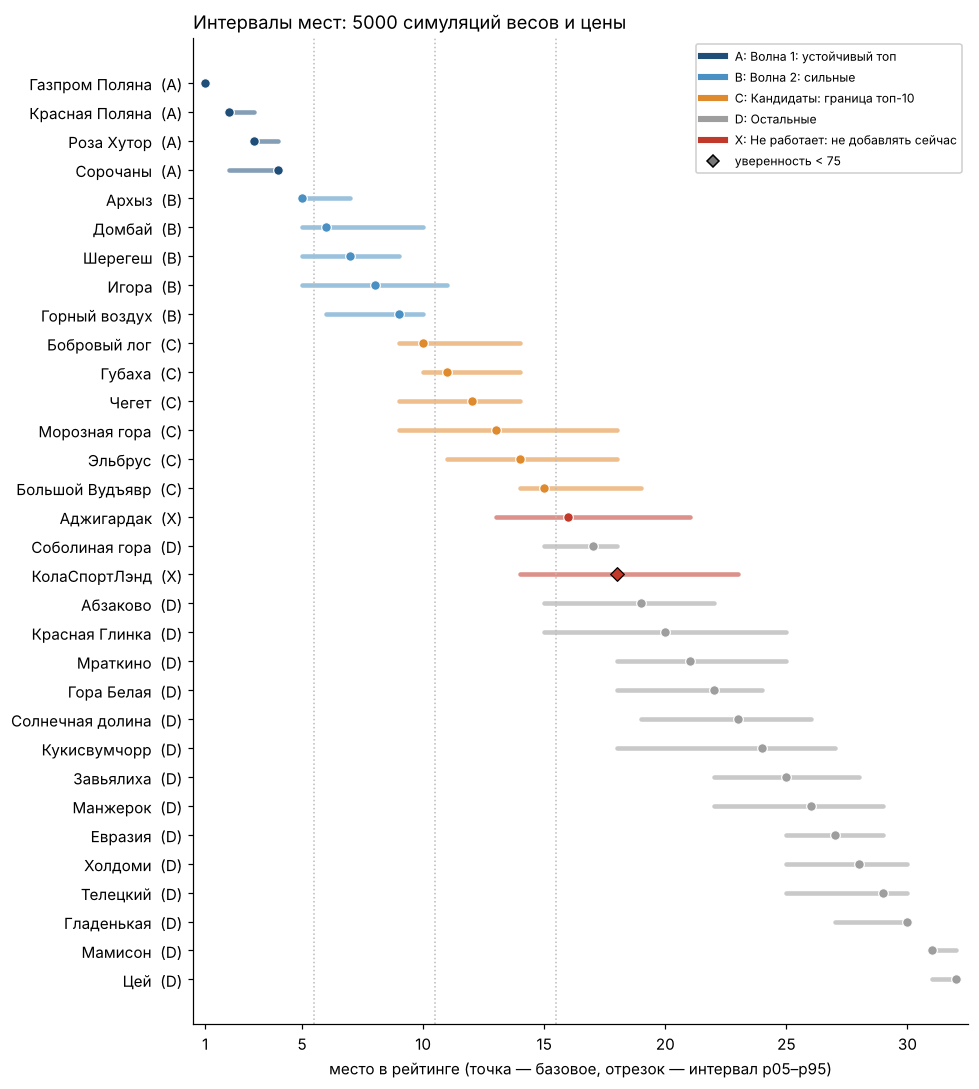

In [6]:
fig, ax = plt.subplots(figsize=(9, 10))
y = range(len(iv))
for i, r in iv.iterrows():
    color = GROUP_COLORS[r["group"]]
    ax.plot([r["rank_p05"], r["rank_p95"]], [i, i], color=color, lw=3, alpha=0.55, solid_capstyle="round")
    ax.scatter(r["rank_default"], i, color=color, s=40, zorder=3,
               marker="o" if r["confidence_score"] >= 75 else "D",
               edgecolor="white" if r["confidence_score"] >= 75 else "black", linewidth=0.8)
ax.set_yticks(list(y))
ax.set_yticklabels([f"{n}  ({g})" for n, g in zip(iv["name_ru"], iv["group"])])
ax.invert_yaxis()
ax.set_xlim(0.5, 32.5)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.set_xlabel("место в рейтинге (точка — базовое, отрезок — интервал p05–p95)")
for k in (5, 10, 15):
    ax.axvline(k + 0.5, color="#bbbbbb", ls=":", lw=1)
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], color=c, lw=4, label=f"{g}: {lbl}") for g, c, lbl in
           [(g, GROUP_COLORS[g], next((x["group_label"] for x in result["intervals"] if x["group"] == g), ""))
            for g in GROUP_COLORS] if lbl]
handles.append(Line2D([0], [0], marker="D", color="w", markeredgecolor="black", markerfacecolor="#777", label="уверенность < 75"))
ax.legend(handles=handles, loc="upper right", fontsize=8, frameon=True, framealpha=0.95)
ax.set_title(f"Интервалы мест: {len(result['simulations'])} симуляций весов и цены", loc="left")
plt.tight_layout()
plt.show()

## 2. Группы приоритета для каталога

Правило задано в `config/stability.yaml` и проверяется сверху вниз; курорт попадает в первую подходящую группу:

| Группа | Условие | Смысл для бизнеса |
|---|---|---|
| **A** | P(место ≤ 5) ≥ 0.8 | Волна 1: добавляем первыми, результат не зависит от разумной смены весов |
| **B** | P(место ≤ 10) ≥ 0.8 | Волна 2: сильные курорты, но порядок внутри группы не значим |
| **C** | P(место ≤ 15) ≥ 0.5 | Кандидаты: решение зависит от весов и недостающих данных |
| **D** | иначе | Остальные |
| **X** | курорт не работает | Не добавляем сейчас, независимо от индекса |

Порог задан через вероятность, а не через «место ≤ N». Поэтому курорт на 10-м месте с широким интервалом не получает статус «топ-10 гарантирован».

In [7]:
groups = (iv.groupby(["group", "group_label"], sort=True)
            .agg(курортов=("resort_id", "size"),
                 места=("rank_default", lambda s: f"{s.min()}–{s.max()}"),
                 индекс=("popularity_score", lambda s: f"{s.min():.1f}–{s.max():.1f}"),
                 средняя_уверенность=("confidence_score", "mean"),
                 без_цены=("has_price", lambda s: int((~s).sum())),
                 курорты=("name_ru", ", ".join))
            .round(1))
groups

,,курортов,места,индекс,средняя_уверенность,без_цены,курорты
group,group_label,,,,,,
A,Волна 1: устойчивый топ,4,1–4,69.4–74.5,93.8,1,"Газпром Поляна, Красная Поляна, Роза Хутор, Со..."
B,Волна 2: сильные,5,5–9,53.7–57.1,90.0,2,"Архыз, Домбай, Шерегеш, Игора, Горный воздух"
C,Кандидаты: граница топ-10,6,10–15,45.2–49.9,91.7,2,"Бобровый лог, Губаха, Чегет, Морозная гора, Эл..."
D,Остальные,15,17–32,27.4–44.1,85.0,9,"Соболиная гора, Абзаково, Красная Глинка, Мрат..."
X,Не работает: не добавлять сейчас,2,16–18,43.6–44.2,60.2,2,"Аджигардак, КолаСпортЛэнд"


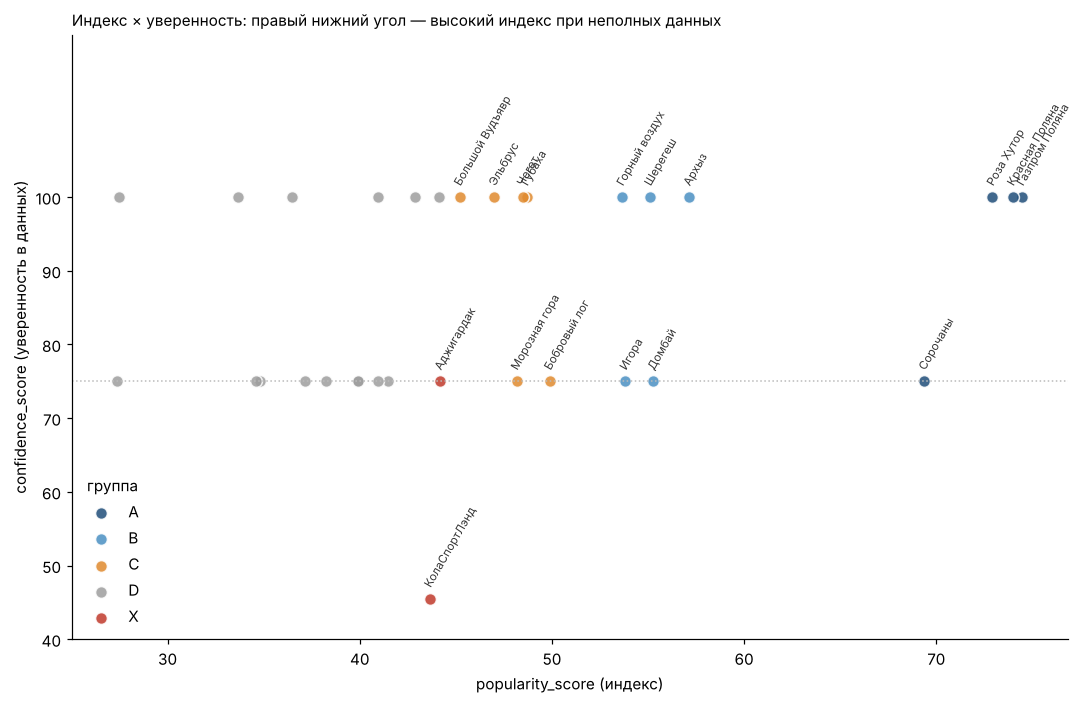

,rank_default,name_ru,group,popularity_score,confidence_score,quality_flags
3,4,Сорочаны,A,69.38,75.0,missing price
5,6,Домбай,B,55.27,75.0,missing price
7,8,Игора,B,53.82,75.0,missing price
9,10,Бобровый лог,C,49.89,75.0,missing price
12,13,Морозная гора,C,48.16,75.0,missing price


In [8]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for g, part in iv.groupby("group"):
    ax.scatter(part["popularity_score"], part["confidence_score"], s=60, color=GROUP_COLORS[g],
               label=g, alpha=0.85, edgecolor="white")
for _, r in iv[iv["group"].isin(["A", "B", "C", "X"])].iterrows():
    ax.annotate(r["name_ru"], (r["popularity_score"], r["confidence_score"]),
                textcoords="offset points", xytext=(2, 6), fontsize=7.5, color="#333",
                rotation=60, ha="left", va="bottom", rotation_mode="anchor")
ax.axhline(75, color="#bbbbbb", ls=":", lw=1)
ax.set_xlabel("popularity_score (индекс)")
ax.set_ylabel("confidence_score (уверенность в данных)")
ax.set_ylim(40, 122)
ax.set_yticks([40, 50, 60, 70, 80, 90, 100])
ax.legend(title="группа", frameon=False, loc="lower left")
ax.set_title("Индекс × уверенность: правый нижний угол — высокий индекс при неполных данных", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

risky = iv[(iv["group"].isin(["A", "B", "C"])) & (iv["confidence_score"] < 100)]
risky[["rank_default", "name_ru", "group", "popularity_score", "confidence_score", "quality_flags"]]

## 3. +20% к весу каждого компонента

Вес компонента умножается на 1.2, остальные компоненты пропорционально уменьшаются до суммы 100. Пропорции показателей внутри компонента сохраняются. `shift > 0` — курорт поднялся.

In [9]:
comp_summary = pd.DataFrame(result["component_summary"])
comp_summary

,component,label,weight_before,weight_after,spearman,mean_abs_shift,max_abs_shift,resort_max_shift,top10_common,top10_out,top10_in
0,demand,Региональный спрос,40.0,48.0,0.9839,1.12,4,Большой Вудъявр,10,,
1,infrastructure,Инфраструктура,25.0,30.0,0.9952,0.62,2,Аджигардак,10,,
2,winter,Зимние условия,20.0,24.0,0.9879,0.94,5,Кукисвумчорр,9,Бобровый лог,Чегет
3,access,Доступность,10.0,12.0,0.9956,0.44,3,Горный воздух,10,,
4,price,Цена,5.0,6.0,0.9989,0.19,1,Губаха,10,,


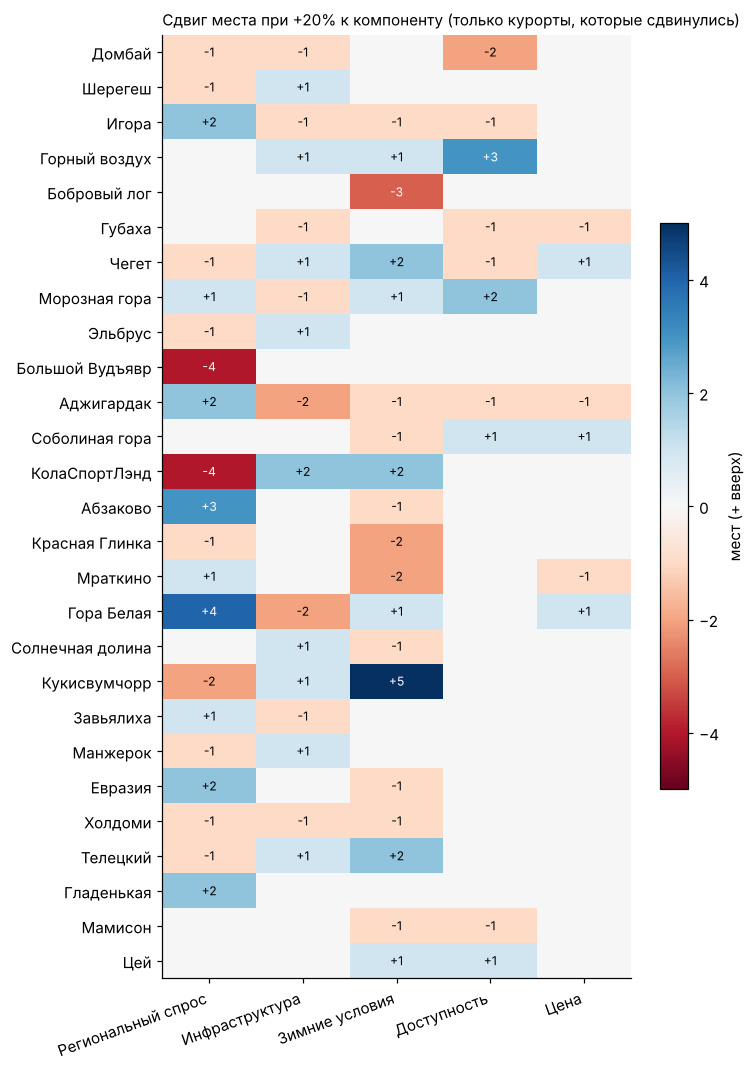

In [10]:
comp = pd.DataFrame(result["component_by_resort"]).sort_values("rank_default")
shift_cols = [f"shift_{c}" for c in st.COMPONENTS]
heat = comp.set_index("name_ru")[shift_cols].rename(columns=lambda c: st.COMPONENT_LABELS[c.removeprefix("shift_")])
heat = heat[(heat != 0).any(axis=1)]

fig, ax = plt.subplots(figsize=(7, 0.32 * len(heat) + 1.2))
im = ax.imshow(heat.values, cmap="RdBu", vmin=-5, vmax=5, aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, rotation=20, ha="right")
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if v:
            ax.text(j, i, f"{v:+d}", ha="center", va="center", fontsize=8, color="white" if abs(v) >= 3 else "black")
ax.set_title("Сдвиг места при +20% к компоненту (только курорты, которые сдвинулись)", loc="left", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.6, label="мест (+ вверх)")
plt.tight_layout()
plt.show()

## 4. Leave-one-out: какие показатели сильнее всего влияют на порядок

Убираем по одному показателю, остальные веса растягиваем до 100. Чем ниже корреляция Спирмена с базовым порядком и чем больше средний сдвиг, тем сильнее показатель определяет рейтинг.

In [11]:
loo = pd.DataFrame(result["leave_one_out"])
loo

,metric,component,weight,spearman,mean_abs_shift,max_abs_shift,resort_max_shift,top10_common,top10_out,top10_in
0,region_trips,Региональный спрос,25.0,0.9065,3.25,8,Игора,8,Бобровый лог; Игора,Чегет; Эльбрус
1,snow_days,Зимние условия,8.0,0.9487,2.06,8,Абзаково,10,,
2,region_growth,Региональный спрос,10.0,0.9600,2.06,7,Морозная гора,8,Горный воздух; Домбай,Чегет; Эльбрус
3,airport,Доступность,8.0,0.9714,1.38,8,Красная Глинка,8,Бобровый лог; Горный воздух,Губаха; Чегет
4,pistes,Инфраструктура,10.0,0.9820,1.31,5,Гора Белая,10,,
5,snowfall,Зимние условия,6.0,0.9861,1.06,4,Абзаково,10,,
6,avg_stay,Региональный спрос,5.0,0.9894,0.81,3,Эльбрус,10,,
7,lodging,Инфраструктура,5.0,0.9897,1.00,3,Морозная гора,9,Бобровый лог,Морозная гора
8,lifts,Инфраструктура,7.0,0.9941,0.69,2,Шерегеш,10,,
9,price,Цена,5.0,0.9963,0.44,2,Чегет,10,,


Три показателя, сильнее всего влияющие на порядок: region_trips, snow_days, region_growth


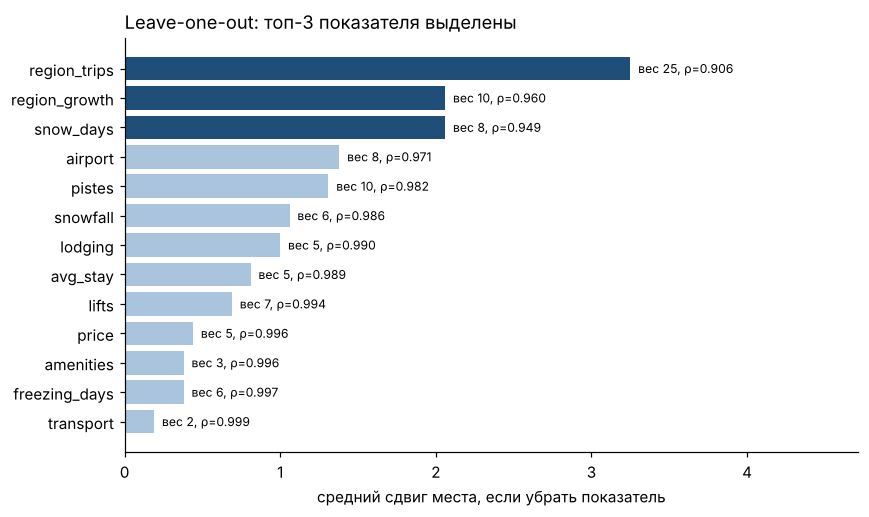

In [12]:
plot = loo.sort_values("mean_abs_shift")
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.barh(plot["metric"], plot["mean_abs_shift"],
               color=["#1f4e79" if i >= len(plot) - 3 else "#a9c4dc" for i in range(len(plot))])
for bar, w, rho in zip(bars, plot["weight"], plot["spearman"]):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
            f"вес {w:g}, ρ={rho:.3f}", va="center", fontsize=8)
ax.set_xlabel("средний сдвиг места, если убрать показатель")
ax.set_title("Leave-one-out: топ-3 показателя выделены", loc="left")
ax.set_xlim(0, plot["mean_abs_shift"].max() * 1.45)
plt.tight_layout()
plt.show()

top3 = loo.head(3)
print("Три показателя, сильнее всего влияющие на порядок:", ", ".join(top3["metric"]))

In [13]:
# Влияние на показатель не пропорционально весу: «сила» = средний сдвиг на 1 пункт веса
loo.assign(сдвиг_на_пункт_веса=(loo["mean_abs_shift"] / loo["weight"]).round(3)) \
   .sort_values("сдвиг_на_пункт_веса", ascending=False)[["metric", "component", "weight", "mean_abs_shift", "сдвиг_на_пункт_веса"]]

,metric,component,weight,mean_abs_shift,сдвиг_на_пункт_веса
1,snow_days,Зимние условия,8.0,2.06,0.258
2,region_growth,Региональный спрос,10.0,2.06,0.206
7,lodging,Инфраструктура,5.0,1.00,0.200
5,snowfall,Зимние условия,6.0,1.06,0.177
3,airport,Доступность,8.0,1.38,0.172
6,avg_stay,Региональный спрос,5.0,0.81,0.162
4,pistes,Инфраструктура,10.0,1.31,0.131
0,region_trips,Региональный спрос,25.0,3.25,0.130
10,amenities,Инфраструктура,3.0,0.38,0.127
8,lifts,Инфраструктура,7.0,0.69,0.099


## 5. Где сбор цены полезнее всего

По ТЗ курорт без цены получает 50 баллов. Здесь для каждого такого курорта считаем место при самой высокой цене (балл 0) и самой низкой (балл 100). Остальные курорты без цены остаются с 50. `swing` — на сколько мест «стоит» неизвестная цена.

In [14]:
pb = pd.DataFrame(result["price_bounds"]).merge(iv[["resort_id", "group"]], on="resort_id")
pb

,resort_id,name_ru,rank_default,rank_if_expensive,rank_if_cheap,swing,group
0,R031,Красная Глинка,20,24,18,6,D
1,R015,КолаСпортЛэнд,18,20,15,5,X
2,R027,Мраткино,21,24,19,5,D
3,R024,Солнечная долина,23,25,20,5,D
4,R014,Кукисвумчорр,24,25,20,5,D
5,R006,Домбай,6,9,5,4,B
6,R018,Морозная гора,13,14,10,4,C
7,R023,Аджигардак,16,19,15,4,X
8,R025,Завьялиха,25,27,23,4,D
9,R017,Холдоми,28,30,26,4,D


In [15]:
# Приоритет сбора: курорты из групп B и C, у которых неизвестная цена может перевести их через границу группы
pb[pb["group"].isin(["B", "C"])].sort_values(["group", "rank_default"])

,resort_id,name_ru,rank_default,rank_if_expensive,rank_if_cheap,swing,group
5,R006,Домбай,6,9,5,4,B
10,R029,Игора,8,9,6,3,B
11,R019,Бобровый лог,10,13,10,3,C
6,R018,Морозная гора,13,14,10,4,C


## 6. Проверка самой проверки: зависят ли группы от параметров симуляции

Если группы меняются при другом разбросе весов, правило слишком хрупкое. Пересчитаем с `concentration` 100 (сильный разброс), 200 (база) и 500 (слабый разброс) и с другим seed.

In [16]:
import copy
variants = {"conc=100": (100, 42), "conc=200 (база)": (200, 42), "conc=500": (500, 42), "conc=200, seed=7": (200, 7)}
rows = result["rows"]
table = iv[["resort_id", "name_ru", "rank_default"]].copy()
for name, (conc, seed) in variants.items():
    c = copy.deepcopy(cfg)
    c["monte_carlo"].update(concentration=conc, seed=seed)
    sims = st.simulate_ranks(rows, result["weights"], n=c["monte_carlo"]["n_simulations"], seed=seed,
                             concentration=conc, price_range=tuple(c["monte_carlo"]["missing_price_score"]))
    ints = st.assign_groups(st.rank_intervals(rows, sims, top_k=(5, 10, 15)),
                            c["groups"], c["default_group"], c["not_operating_group"])
    table[name] = table["resort_id"].map({x["resort_id"]: x["group"] for x in ints})
changed = table[table[list(variants)].nunique(axis=1) > 1]
print("Курортов, у которых группа зависит от параметров:", len(changed), "из 32")
changed

Курортов, у которых группа зависит от параметров: 0 из 32


,resort_id,name_ru,rank_default,conc=100,conc=200 (база),conc=500,"conc=200, seed=7"


## 7. Сохранение результатов

Те же таблицы пишет `make stability`; ячейка нужна, чтобы файлы в `data/mart/` соответствовали тому, что показано выше.

In [17]:
st.main(ROOT)

Сценарий: verified, симуляций: 5000
  A Волна 1: устойчивый топ: Газпром Поляна, Красная Поляна, Роза Хутор, Сорочаны
  B Волна 2: сильные: Архыз, Домбай, Шерегеш, Игора, Горный воздух
  C Кандидаты: граница топ-10: Бобровый лог, Губаха, Чегет, Морозная гора, Эльбрус, Большой Вудъявр
  D Остальные: Соболиная гора, Абзаково, Красная Глинка, Мраткино, Гора Белая, Солнечная долина, Кукисвумчорр, Завьялиха, Манжерок, Евразия, Холдоми, Телецкий, Гладенькая, Мамисон, Цей
  X Не работает: не добавлять сейчас: Аджигардак, КолаСпортЛэнд

Сильнее всего порядок зависит от (leave-one-out, по Спирмену):
  region_trips   rho=0.906, сдвиг в среднем 3.25 места
  snow_days      rho=0.949, сдвиг в среднем 2.06 места
  region_growth  rho=0.960, сдвиг в среднем 2.06 места


## Выводы шага 6

*Числа ниже — для сценария `verified`, 5000 симуляций, seed 42. После обновления данных пересчитайте ноутбук: текст выводов нужно сверить с таблицами выше.*

**Данные (что показывает расчёт):**

1. **Группа A — 4 курорта: Газпром Поляна, Красная Поляна, Роза Хутор, Сорочаны.** В 100% симуляций они в топ-5, интервалы мест не выходят за 1–4. Это устойчивый результат: его не меняет ни разумная смена весов, ни неизвестная цена Сорочан.
2. **Группа B — Архыз, Домбай, Шерегеш, Игора, Горный воздух.** В топ-10 почти во всех симуляциях (95–100%), но их интервалы перекрываются (места 5–11). Говорить «Домбай 6-й, а Шерегеш 7-й» некорректно: это одна группа.
3. **Группа C — граница топ-10:** Бобровый лог (P(топ-10) ≈ 0.53), Губаха, Чегет, Морозная гора, Эльбрус, Большой Вудъявр. Здесь место определяется весами и недостающими данными.
4. **Аджигардак и КолаСпортЛэнд** (16 и 18 места) не работают и вынесены в группу X независимо от индекса.
5. **Три показателя, сильнее всего влияющие на порядок (leave-one-out):** поездки в регион, снежные дни и рост поездок. Без поездок в регион средний сдвиг — 3.3 места, а из топ-10 выпадают Бобровый лог и Игора.
6. **+20% к компонентам** почти не меняет порядок (Спирмен ≥ 0.98). Топ-10 меняется только при +20% к зимним условиям: Бобровый лог ↔ Чегет.
7. **В пересчёте на пункт веса** сильнее всего действуют снежные дни и рост поездок. Поездки в регион влияют больше всех в сумме, но в основном за счёт большого веса (25).
8. **У курортов без цены интервал мест почти вдвое шире:** в среднем 6.3 места против 3.6 у курортов с ценой.

**Допущения:**

- Разброс весов `concentration=200` (90% интервал: вес 25 — примерно ±20%, вес 5 — примерно ±50%) — наше решение, а не требование ТЗ. Раздел 6 показывает, что группы от него не зависят: при concentration 100 и 500 и другом seed ни один курорт не меняет группу.
- Курорты без цены получают случайный ценовой балл от 0 до 100. Это честнее фиксированных 50, но цена может быть и «хуже худшей» в выборке.
- Признаки (OSM, ERA5, Росстат) в симуляции не меняются. Ошибки в самих данных интервалы не учитывают: они отражают только неопределённость весов и цены.
- Региональный спрос одинаков у всех курортов региона. Поэтому три курорта Краснодарского края получают одинаковый, и самый сильный, вклад этого показателя.

**Что делать дальше:**

- Собрать цены в первую очередь для курортов групп B и C без цены (таблица в разделе 5): Домбай, Игора, Бобровый лог, Морозная гора. Это сузит интервалы именно там, где решается состав второй волны.
- На дашборде показывать не только место, но и интервал и группу (график раздела 1).